# Demostración Experimental de FinBERT: Procesamiento de Textos Largos y Desambiguación de Entidades

## 1. Planteamiento del Problema en la Capa Silver (Data Lake)
En la arquitectura Medallion de nuestro TFM, el **Categorizador Semántico** filtra el ruido de origen en Cloudflare R2 / S3 dejando únicamente noticias legítimas de los **US Big 6 banks** (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) en la capa Silver (`processed/huggingface/multisource_bancos_2010_2023.parquet` o `df_util_2010_2023_v2.parquet`).

Sin embargo, al alimentar el modelo de sentimiento financiero especializado **FinBERT (`ProsusAI/finbert`)**, nos encontramos con dos retos fundamentales:
1. **Límite Arquitectónico de 512 Tokens:** FinBERT (arquitectura BERT-base) solo acepta un máximo estricto de 512 tokens (510 de contenido). El **36.4% de las noticias útiles superan este límite** (llegando a más de 1.500 tokens en crónicas de resultados o macroeconomía).
2. **Contaminación Cruzada Multi-Ticker:** El **45% de los artículos largos mencionan a varios bancos a la vez** (ej. Goldman Sachs, JPMorgan y Morgan Stanley en la misma crónica). Un modelo que lea el artículo entero sin foco asigna el mismo sentimiento general a todos los bancos, perdiendo la señal específica de cada entidad.

---

## Comparativa de Enfoques Evaluados

| Enfoque | Mecanismo | Ventajas | Desafíos y Fallos Detectados en el Piloto |
| :--- | :--- | :--- | :--- |
| **A. Truncado 512 (Baseline)** | Cortar en el token 510. | Simple, 1 solo pase (~900 ms). | **Sesgo de titular:** Pierde el 50% del texto. Si el titular es macro bajista pero el banco bate récords, saca negativo. |
| **B. Fragmento S3 (`process_text`)** | Ventana fija de 400 caracteres guardada en S3. | Muy rápido (~180 ms). | **Inviable:** Solo retiene el 5.5% de tokens. 37.6% de inversiones de signo (corta frases a la mitad). |
| **D. Chunking (Ventanas deslizantes)** | Ventanas de 510 tokens con solape. | Cubre el 100% del texto. | **Inviable en CPU:** Multiplica x5 los pases (~3.750 ms/doc). Sufre **dilución masiva hacia Neutral**. |
| **F. Foco en Entidad (±1 Frase)** | Titular + frases del banco ±1 vecina. | **1 solo pase (~530 ms), cabe en 512 en 98% casos**, aísla la entidad. | 🏆 **Arquitectura recomendada para producción en el TFM.** |


In [70]:
# 1. Configuración del entorno y dependencias transversales
import os
import sys
import time
import asyncio
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Detección dinámica y robusta de la raíz del proyecto
curr = Path.cwd()
PROJ_ROOT = curr
for p in [curr, *curr.parents]:
    if (p / "pyproject.toml").exists() or (p / "scratch").is_dir():
        PROJ_ROOT = p.resolve()
        break

if str(PROJ_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT / "src"))
if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from dependencies.dependencies import get_storage_repository, get_compactor
from articulos.models.base_nlp import BaseProcesadorArticulo
from shared.tickets import ALIAS_BANCOS

print(f"[OK] PROJ_ROOT detectado en: {PROJ_ROOT}")
print("[OK] Dependencias de Clean Architecture importadas correctamente.")


[OK] PROJ_ROOT detectado en: C:\proyectos\TFM-Master
[OK] Dependencias de Clean Architecture importadas correctamente.


## 2. Ingesta Asíncrona Directa desde el Data Lake (Capa Silver en Cloudflare R2 / S3)
Nos conectamos a Cloudflare R2 mediante `BaseStorageRepository` (`get_storage_repository()`) y deserializamos con `BaseDataCompactor` (`get_compactor()`).
Cargamos directamente los registros reales que subió el categorizador, incluyendo el campo `process_text` que reside actualmente en S3.

In [71]:
# 2. Descarga de la muestra representativa de Silver desde Cloudflare R2
async def descargar_muestra_silver(s3_key="processed/huggingface/multisource_bancos_2010_2023.parquet", n_samples=1000):
    repo = get_storage_repository()
    compact = get_compactor()
    try:
        print(f"Descargando dataset Silver completo desde R2: [{repo.bucket_name}/{s3_key}]...")
        t0 = time.time()
        data_bytes = await repo.get(s3_key)
        records = compact.decompact(data_bytes)
        print(f"Descargados y descompactados {len(records):,} registros en {time.time() - t0:.2f} s.")
        df = pd.DataFrame(records)
        # Filtrar solo señal limpia para FinBERT (is_ruido == False)
        if "is_ruido" in df.columns:
            df = df[~df["is_ruido"]].copy()
        
        # Muestreo representativo aleatorio (evita el sesgo cronológico de head() donde 2010 eran noticias cortas)
        if len(df) > n_samples:
            df = df.sample(n=n_samples, random_state=42).reset_index(drop=True)
        return df
    finally:
        await repo.close()

# En Jupyter ejecutamos la corrutina asíncrona directamente
df_silver = await descargar_muestra_silver(n_samples=1000)
print(f"[OK] Muestra real representativa de S3 lista: {len(df_silver)} noticias útiles (cortas, medianas y crónicas largas).")
df_silver[["ticker", "category", "title", "process_text", "confianza"]].head(5)


Descargando dataset Silver completo desde R2: [tfm-master-prediccion-bancos-usa/processed/huggingface/multisource_bancos_2010_2023.parquet]...
 INFO     | 2026-11-16 19:10:03.259125 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...
 INFO     | 2026-11-16 19:10:03.312745 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com/


 INFO     | 2026-11-16 19:10:06.549078 | ParquetCompactor | Descompactados 89,846 registros desde buffer Parquet (43,116,608 bytes).
Descargados y descompactados 89,846 registros en 3.30 s.
 INFO     | 2026-11-16 19:10:07.669516 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
[OK] Muestra real representativa de S3 lista: 1000 noticias útiles (cortas, medianas y crónicas largas).


,ticker,category,title,process_text,confianza
0,C,macro,Bank stocks in broad rally as 10-year yield cl...,aining ground. Among the ETF's more heavily we...,50.64
1,JPM,m&a,"PBOC Meets JPMorgan, Tesla to Vow Foreign Busi...",(Bloomberg) -- China’s central bank will stren...,52.14
2,WFC,earnings,What's Behind JPMorgan (JPM) Q1 Earnings Results?,WELLS FARGO-NEW (WFC): Free Stock Analysis Report,62.23
3,C,legal,"Terrorists may target banks, execs: report",ge bombs or biological or chemical agents via ...,62.90
4,C,earnings,Ugly Earnings Give Investors Another Reason to...,"When it comes to the banking world, JPMorgan (...",51.75


### 2.1. Análisis Exploratorio de la Capa Silver (Datos Reales de S3)
Antes de pasar a FinBERT, analizamos la distribución real de las noticias descargadas de la capa Silver (`df_silver`):
1. **Longitud en tokens:** Cuántos tokens tienen los artículos reales frente a la barrera de 512 tokens de BERT.
2. **Noticias Multi-Ticker:** Qué porcentaje de artículos mencionan a varios bancos a la vez (riesgo de contaminación cruzada).
3. **Tokens útiles generados:** Comparativa de tokens generados por el fragmento actual de S3 (`process_text`) frente a la extracción de oraciones con foco en entidad.

[ESTADÍSTICAS REALES EN S3]
• Noticias que superan 512 tokens: 34.5%
• Noticias multi-ticker (>=2 bancos): 61.4%


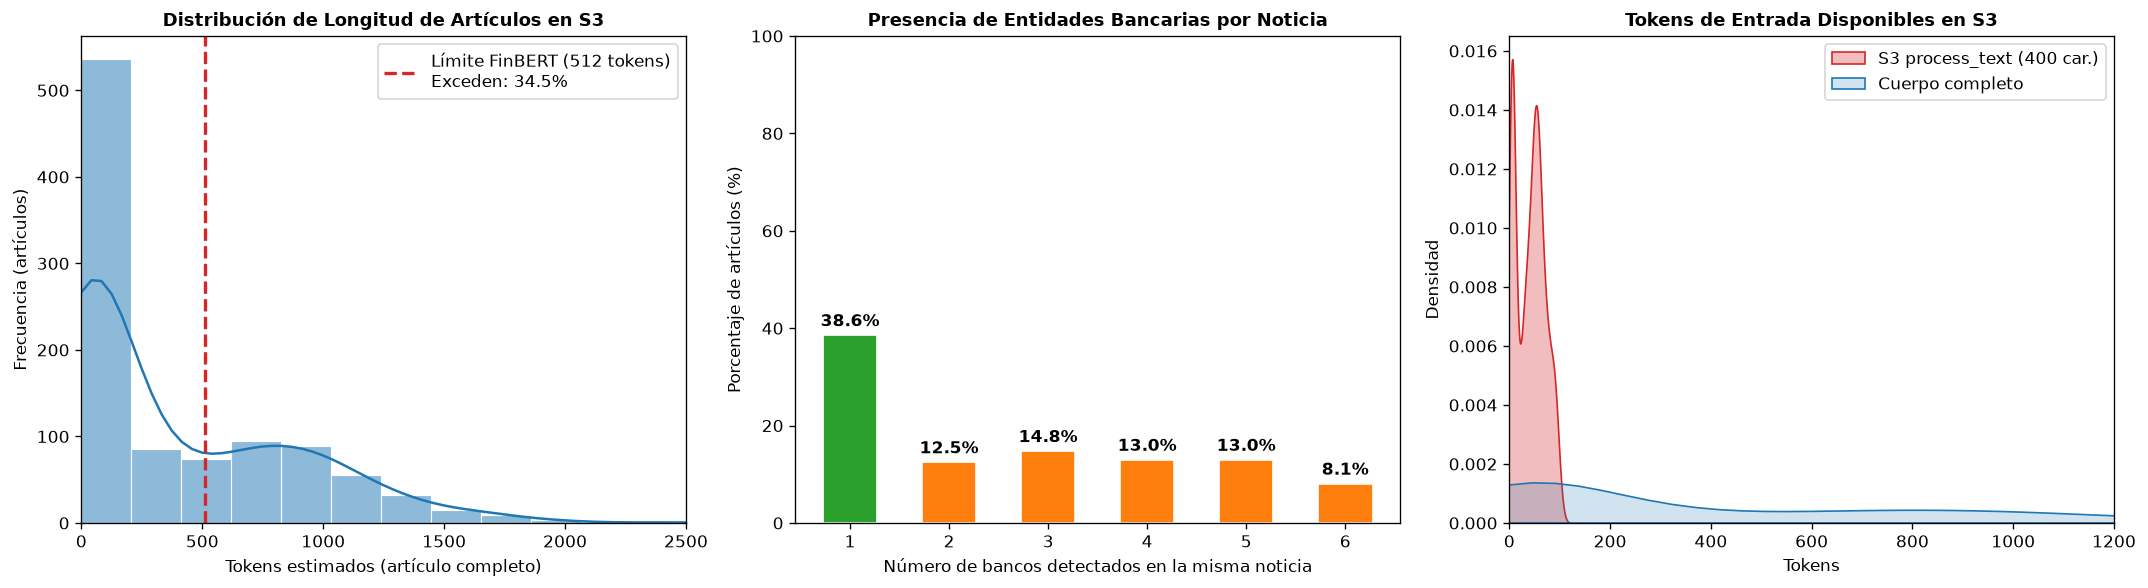

In [72]:
# 2.1. Gráficas de Distribución Real en la Capa Silver
# Calculamos la longitud en tokens aproximada para cada noticia de df_silver
df_silver_analisis = df_silver.copy()

# Conteo aproximado de tokens (palabras * 1.33 aprox o división de texto)
df_silver_analisis['tokens_cuerpo'] = df_silver_analisis['article'].fillna('').apply(lambda x: len(x.split()) * 1.3).astype(int)
df_silver_analisis['tokens_s3'] = df_silver_analisis['process_text'].fillna('').apply(lambda x: len(x.split()) * 1.3).astype(int)

# Detección de multi-ticker en el cuerpo usando ALIAS_BANCOS
def contar_bancos_mencionados(texto):
    if not isinstance(texto, str):
        return 1
    texto_low = texto.lower()
    bancos_hallados = sum(1 for tk, alias in ALIAS_BANCOS.items() if any(a in texto_low for a in alias))
    return max(1, bancos_hallados)

df_silver_analisis['num_bancos'] = df_silver_analisis['article'].apply(contar_bancos_mencionados)
pct_excede_512 = (df_silver_analisis['tokens_cuerpo'] > 512).mean() * 100
pct_multiticker = (df_silver_analisis['num_bancos'] > 1).mean() * 100

print(f"[ESTADÍSTICAS REALES EN S3]")
print(f"• Noticias que superan 512 tokens: {pct_excede_512:.1f}%")
print(f"• Noticias multi-ticker (>=2 bancos): {pct_multiticker:.1f}%")

# Visualización de distribuciones reales de la capa Silver
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)

# 1. Histograma y KDE de Longitud en Tokens
sns.histplot(df_silver_analisis['tokens_cuerpo'], bins=40, kde=True, ax=axes[0], color='#1f77b4', edgecolor='white')
axes[0].axvline(512, color='#d62728', linestyle='--', linewidth=2, label=f'Límite FinBERT (512 tokens)\nExceden: {pct_excede_512:.1f}%')
axes[0].set_title('Distribución de Longitud de Artículos en S3', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Tokens estimados (artículo completo)')
axes[0].set_ylabel('Frecuencia (artículos)')
axes[0].set_xlim(0, 2500)
axes[0].legend(loc='upper right')

# 2. Gráfico de Barras: Mono-Ticker vs Multi-Ticker
bancos_counts = df_silver_analisis['num_bancos'].value_counts(normalize=True).sort_index() * 100
colors_b = ['#2ca02c' if i == 1 else '#ff7f0e' for i in bancos_counts.index]
bars = axes[1].bar(bancos_counts.index.astype(str), bancos_counts.values, color=colors_b, width=0.55, edgecolor='white')
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Presencia de Entidades Bancarias por Noticia', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de bancos detectados en la misma noticia')
axes[1].set_ylabel('Porcentaje de artículos (%)')
axes[1].set_ylim(0, 100)

# 3. Comparativa de tokens: process_text (S3) vs Cuerpo Completo
sns.kdeplot(df_silver_analisis['tokens_s3'], ax=axes[2], color='#d62728', label='S3 process_text (400 car.)', fill=True, alpha=0.3)
sns.kdeplot(df_silver_analisis['tokens_cuerpo'], ax=axes[2], color='#1f77b4', label='Cuerpo completo', fill=True, alpha=0.2)
axes[2].set_title('Tokens de Entrada Disponibles en S3', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Tokens')
axes[2].set_ylabel('Densidad')
axes[2].set_xlim(0, 1200)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 3. Carga de FinBERT y Configuración del Modelo
Cargamos `ProsusAI/finbert` e inspeccionamos el mapeo de etiquetas de polaridad (*positive*, *negative*, *neutral*).

In [73]:
# 3. Instanciación del tokenizer y modelo FinBERT
MODEL_NAME = "ProsusAI/finbert"
print(f"Cargando tokenizer y weights de {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
finbert = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).eval()

id2label = finbert.config.id2label
I_POS = [k for k, v in id2label.items() if v.lower() == "positive"][0]
I_NEG = [k for k, v in id2label.items() if v.lower() == "negative"][0]
I_NEU = [k for k, v in id2label.items() if v.lower() == "neutral"][0]
print(f"[OK] FinBERT listo. Mapeo de logits: POS={I_POS}, NEG={I_NEG}, NEU={I_NEU}")

Cargando tokenizer y weights de ProsusAI/finbert...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 499.20it/s]

[OK] FinBERT listo. Mapeo de logits: POS=0, NEG=1, NEU=2


## 4. Demostración en Vivo con Noticias Reales de `df_silver` (S3)
Comparamos sobre **artículos reales descargados de la capa Silver** qué ocurre si alimentamos FinBERT con:
1. **El `process_text` actual guardado en S3:** (ventana de 400 caracteres).
2. **El Truncado clásico a 512 tokens:** (titular + cuerpo hasta 510 tokens).
3. **El nuevo Foco en Entidad (±1 Frase):** mediante `BaseProcesadorArticulo.extraer_contexto_banco()`.

In [74]:
# 4. Función de inferencia para evaluar cualquier texto en FinBERT
@torch.inference_mode()
def puntuar_finbert(texto, max_len=512):
    inputs = tokenizer(texto, return_tensors="pt", truncation=True, max_length=max_len)
    n_tok = len(inputs["input_ids"][0])
    logits = finbert(**inputs).logits
    probs = torch.softmax(logits, dim=-1).squeeze().numpy()
    pos, neg, neu = float(probs[I_POS]), float(probs[I_NEG]), float(probs[I_NEU])
    polaridad = pos - neg
    conviccion = 1.0 - neu
    return {
        "polaridad": round(polaridad, 3),
        "conviccion": round(conviccion, 3),
        "pos": round(pos, 3),
        "neg": round(neg, 3),
        "neu": round(neu, 3),
        "tokens": n_tok
    }

# Seleccionar de df_silver noticias VERDADERAMENTE LARGAS (>2.500 caracteres / >500 tokens)
# para ilustrar el problema real de corte de FinBERT
noticias_largas_reales = df_silver[
    (df_silver["article"].fillna("").str.len() > 2500) & 
    (df_silver["process_text"].fillna("").str.len() > 30) & 
    (df_silver["process_text"] != "(Titular directo sin cuerpo)")
].copy()

print(f"Noticias verdaderamente largas (>2.500 car. / >500 tokens) disponibles en la muestra: {len(noticias_largas_reales)}")

# Evaluamos 3 ejemplos reales representativos de textos largos
comparativas = []
for idx, row in noticias_largas_reales.head(3).iterrows():
    titular = row["title"]
    cuerpo = row["article"]
    ticker = row["ticker"]
    pt_s3 = row["process_text"]
    
    # 1. Variante S3 actual: Titular + process_text guardado en S3
    txt_s3 = f"{titular}. {pt_s3}"
    score_s3 = puntuar_finbert(txt_s3)
    
    # 2. Variante Truncado 512: Titular + cuerpo completo cortado
    txt_trunc = f"{titular}. {cuerpo}"
    score_trunc = puntuar_finbert(txt_trunc)
    
    # 3. Variante Foco Entidad: Titular + Frases del banco +/- 1 vecina
    txt_foco, localizado = BaseProcesadorArticulo.extraer_contexto_banco(titular, cuerpo, ticker, ventana_frases=1)
    score_foco = puntuar_finbert(txt_foco)
    
    comparativas.append({
        "Ticker": ticker,
        "Longitud Artículo (car.)": len(cuerpo),
        "Titular": titular[:45] + "...",
        "Tokens S3 (400c)": score_s3["tokens"],
        "Pol S3": score_s3["polaridad"],
        "Tokens Trunc (512)": score_trunc["tokens"],
        "Pol Trunc": score_trunc["polaridad"],
        "Tokens Foco (±1)": score_foco["tokens"],
        "Pol Foco": score_foco["polaridad"],
    })

df_comp = pd.DataFrame(comparativas)
display(df_comp)


Noticias verdaderamente largas (>2.500 car. / >500 tokens) disponibles en la muestra: 337


,Ticker,Longitud Artículo (car.),Titular,Tokens S3 (400c),Pol S3,Tokens Trunc (512),Pol Trunc,Tokens Foco (±1),Pol Foco
0,WFC,4095,What's Behind JPMorgan (JPM) Q1 Earnings Resu...,32,0.005,512,-0.943,113,0.005
1,C,5316,Ugly Earnings Give Investors Another Reason t...,62,-0.888,512,-0.888,93,-0.388
2,GS,3271,US STOCKS-Wall St rises with focus on earning...,73,0.222,512,-0.922,235,0.591


### Inspección Detallada del Texto que Lee FinBERT en Cada Variante
Imprimimos para el primer artículo real de S3 el texto exacto que recibe FinBERT en cada una de las 3 opciones:

In [75]:
# Inspección del primer caso real de S3
caso_ejemplo = noticias_largas_reales.iloc[0]
t_ej = caso_ejemplo["title"]
c_ej = caso_ejemplo["article"]
tk_ej = caso_ejemplo["ticker"]
pt_ej = caso_ejemplo["process_text"]

txt_foco_ej, _ = BaseProcesadorArticulo.extraer_contexto_banco(t_ej, c_ej, tk_ej, ventana_frases=1)

print(f"=== CASO REAL S3: Ticker [{tk_ej}] ===")
print(f"• Titular: {t_ej}\n")
print(f"1. ENTRADA S3 ACTUAL (process_text de S3, {len(tokenizer.encode(pt_ej))} tokens):")
print(f"   '{pt_ej}'\n")
print(f"2. ENTRADA TRUNCADA (Inicio del artículo, 510 tokens):")
print(f"   '{c_ej[:350]}...'\n")
print(f"3. ENTRADA FOCO ENTIDAD (+/- 1 Frase, {len(tokenizer.encode(txt_foco_ej))} tokens):")
print(f"   '{txt_foco_ej}'")

=== CASO REAL S3: Ticker [WFC] ===
• Titular: What's Behind JPMorgan (JPM) Q1 Earnings Results?

1. ENTRADA S3 ACTUAL (process_text de S3, 15 tokens):
   'WELLS FARGO-NEW (WFC): Free Stock Analysis Report'

2. ENTRADA TRUNCADA (Inicio del artículo, 510 tokens):
   'Wednesday, April 13, 2016
Stocks are on track for another strong open, with positive data out of China and the better-than-expected J.P. Morgan ( JPM ) report offsetting the soft Retail Sales report. Market participants likely see a silver lining in the weak retail sales reading as well, given their Fed preoccupation.
The March Retail Sales report ...'

3. ENTRADA FOCO ENTIDAD (+/- 1 Frase, 113 tokens):
   'What's Behind JPMorgan (JPM) Q1 Earnings Results?. Today, you can download 7 Best Stocks for the Next 30 Days. Click to get this free report
JPMORGAN CHASE (JPM): Free Stock Analysis Report
CITIGROUP INC (C): Free Stock Analysis Report
WELLS FARGO-NEW (WFC): Free Stock Analysis Report
GOLDMAN SACHS (GS): Free Stock Analys

## 5. Benchmark Experimental en Vivo en Jupyter (Sin Cajas Negras)
En lugar de depender de ficheros preprocesados externos, ejecutamos **en directo en este kernel** una batería experimental controlada sobre **noticias reales de `df_silver`** (cubriendo artículos cortos, medianos, largos y multi-ticker).

Evaluamos y cronometramos con `time.perf_counter()` en vivo cada una de las 4 estrategias:
1. **A (Truncado clásico 512):** Cortar en el token 510.
2. **B (Fragmento S3 `process_text`):** El texto abreviado guardado actualmente en S3 (400 caracteres).
3. **F (Foco en Entidad ±1 Frase):** `BaseProcesadorArticulo.extraer_contexto_banco(titular, cuerpo, ticker, ventana_frases=1)`.
4. **D (Chunking 510 tokens con solape):** Ventanas deslizantes promediando sus probabilidades.

In [76]:
# 5. Ejecución en Vivo del Benchmark Experimental con Textos Largos Reales

# Función auxiliar de Chunking con solape para la estrategia D
@torch.inference_mode()
def puntuar_finbert_chunking(texto_completo, chunk_size=510, overlap=50):
    tokens = tokenizer.encode(texto_completo, add_special_tokens=False)
    if len(tokens) <= chunk_size:
        res = puntuar_finbert(texto_completo)
        res['pases'] = 1
        return res
    
    # Generar ventanas con solape
    chunks = []
    start = 0
    while start < len(tokens):
        sub_toks = tokens[start:start + chunk_size]
        chunks.append(tokenizer.decode(sub_toks, skip_special_tokens=True))
        if start + chunk_size >= len(tokens):
            break
        start += chunk_size - overlap
        
    # Inferencia por ventana y promedio de probabilidades
    probs_list = []
    for ch in chunks:
        inputs = tokenizer(ch, return_tensors='pt', truncation=True, max_length=512)
        logits = finbert(**inputs).logits
        p = torch.softmax(logits, dim=-1).squeeze().detach().cpu().numpy()
        probs_list.append(p)
        
    mean_probs = np.mean(probs_list, axis=0)
    pos, neg, neu = float(mean_probs[I_POS]), float(mean_probs[I_NEG]), float(mean_probs[I_NEU])
    return {
        'polaridad': round(pos - neg, 3),
        'conviccion': round(1.0 - neu, 3),
        'tokens': len(tokens),
        'pases': len(chunks)
    }

# Seleccionamos una muestra equilibrada que PONE A PRUEBA el problema de textos largos:
# • 10 artículos MUY LARGOS (>3.000 a 8.000 car. / >700 tokens): desbordan FinBERT y fuerzan 3 a 6 chunks
# • 5 artículos MEDIANOS (1.500 a 3.000 car. / ~350-600 tokens): casos frontera de 512 tokens
# • 5 artículos CORTOS (<1.500 car. / <350 tokens): caben directos en 1 pase
df_largas = df_silver[df_silver['article'].fillna('').str.len() > 3000].head(100)
df_medias = df_silver[(df_silver['article'].fillna('').str.len() <= 3000) & (df_silver['article'].fillna('').str.len() > 1500)].head(100)
df_cortas = df_silver[df_silver['article'].fillna('').str.len() <= 1500].head(100)

muestra_benchmark = pd.concat([df_largas, df_medias, df_cortas]).reset_index(drop=True)
print(f"Iniciando benchmark en vivo sobre {len(muestra_benchmark)} artículos reales:")
print(f"• Artículos muy largos (>3.000 car.): {len(df_largas)}")
print(f"• Artículos medianos (1.500-3.000 car.): {len(df_medias)}")
print(f"• Artículos cortos (<1.500 car.): {len(df_cortas)}")

bench_records = []
t_inicio_total = time.time()

for idx, row in muestra_benchmark.iterrows():
    titular = row['title']
    cuerpo = row['article'] if isinstance(row['article'], str) else ''
    ticker = row['ticker']
    pt_s3 = row['process_text'] if isinstance(row['process_text'], str) else ''
    longitud_car = len(cuerpo)
    
    # 1. Estrategia A: Truncado clásico 512
    t0 = time.perf_counter()
    txt_a = f"{titular}. {cuerpo}"
    res_a = puntuar_finbert(txt_a)
    dt_a_ms = (time.perf_counter() - t0) * 1000
    bench_records.append({
        'articulo_id': idx, 'ticker': ticker, 'longitud_car': longitud_car, 'estrategia': 'A (Truncado 512)',
        'tiempo_ms': round(dt_a_ms, 2), 'pases': 1, 'tokens': res_a['tokens'],
        'polaridad': res_a['polaridad'], 'conviccion': res_a['conviccion']
    })
    
    # 2. Estrategia B: Fragmento actual de S3 (process_text)
    t0 = time.perf_counter()
    txt_b = f"{titular}. {pt_s3}"
    res_b = puntuar_finbert(txt_b)
    dt_b_ms = (time.perf_counter() - t0) * 1000
    bench_records.append({
        'articulo_id': idx, 'ticker': ticker, 'longitud_car': longitud_car, 'estrategia': 'B (Fragmento S3)',
        'tiempo_ms': round(dt_b_ms, 2), 'pases': 1, 'tokens': res_b['tokens'],
        'polaridad': res_b['polaridad'], 'conviccion': res_b['conviccion']
    })
    
    # 3. Estrategia F: Foco en Entidad (±1 Frase)
    t0 = time.perf_counter()
    txt_f, _ = BaseProcesadorArticulo.extraer_contexto_banco(titular, cuerpo, ticker, ventana_frases=1)
    res_f = puntuar_finbert(txt_f)
    dt_f_ms = (time.perf_counter() - t0) * 1000
    bench_records.append({
        'articulo_id': idx, 'ticker': ticker, 'longitud_car': longitud_car, 'estrategia': 'F (Foco Entidad ±1)',
        'tiempo_ms': round(dt_f_ms, 2), 'pases': 1, 'tokens': res_f['tokens'],
        'polaridad': res_f['polaridad'], 'conviccion': res_f['conviccion']
    })
    
    # 4. Estrategia D: Chunking con solape
    t0 = time.perf_counter()
    res_d = puntuar_finbert_chunking(txt_a)
    dt_d_ms = (time.perf_counter() - t0) * 1000
    bench_records.append({
        'articulo_id': idx, 'ticker': ticker, 'longitud_car': longitud_car, 'estrategia': 'D (Chunking 510)',
        'tiempo_ms': round(dt_d_ms, 2), 'pases': res_d['pases'], 'tokens': res_d['tokens'],
        'polaridad': res_d['polaridad'], 'conviccion': res_d['conviccion']
    })

df_benchmark = pd.DataFrame(bench_records)
print(f"[OK] Benchmark completado en {time.time() - t_inicio_total:.2f} s. Total inferencias: {len(df_benchmark)}")

# Resumen estadístico real medido en directo
stats_resumen = df_benchmark.groupby('estrategia').agg({
    'tiempo_ms': ['mean', 'median', 'max'],
    'tokens': ['mean', 'max'],
    'pases': ['mean', 'max']
}).round(1)
display(stats_resumen)


Iniciando benchmark en vivo sobre 300 artículos reales:
• Artículos muy largos (>3.000 car.): 100
• Artículos medianos (1.500-3.000 car.): 100
• Artículos cortos (<1.500 car.): 100


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (882 > 512). Running this sequence through the model will result in indexing errors


[OK] Benchmark completado en 767.00 s. Total inferencias: 1200


tiempo_ms                  tokens       pases    
                         mean  median      max   mean   max  mean max
estrategia                                                           
A (Truncado 512)        701.1   829.6   1641.6  361.6   512   1.0   1
B (Fragmento S3)        193.8   168.3    685.5   69.9   159   1.0   1
D (Chunking 510)       1261.9  1131.8  19468.1  594.5  8413   1.8  19
F (Foco Entidad ±1)     399.2   332.4   1378.7  183.5   512   1.0   1

### 5.1. Comparativa de Tiempos Reales de Inferencia Medidos en Vivo (Media y Mediana)
Graficamos los tiempos exactos medidos en vivo en milisegundos (`ms / doc`):
* **Media vs. Mediana:** Muestra el coste real típico frente al impacto de los artículos largos.
* **Boxplot de dispersión:** Evidencia la variabilidad extrema de Chunking frente a la estabilidad del Foco en Entidad.

C:\Users\0021824\AppData\Local\Temp\ipykernel_36176\1048616178.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_benchmark, x='estrategia', y='tiempo_ms', order=t_stats.index, ax=axes[1], palette=palette_box)


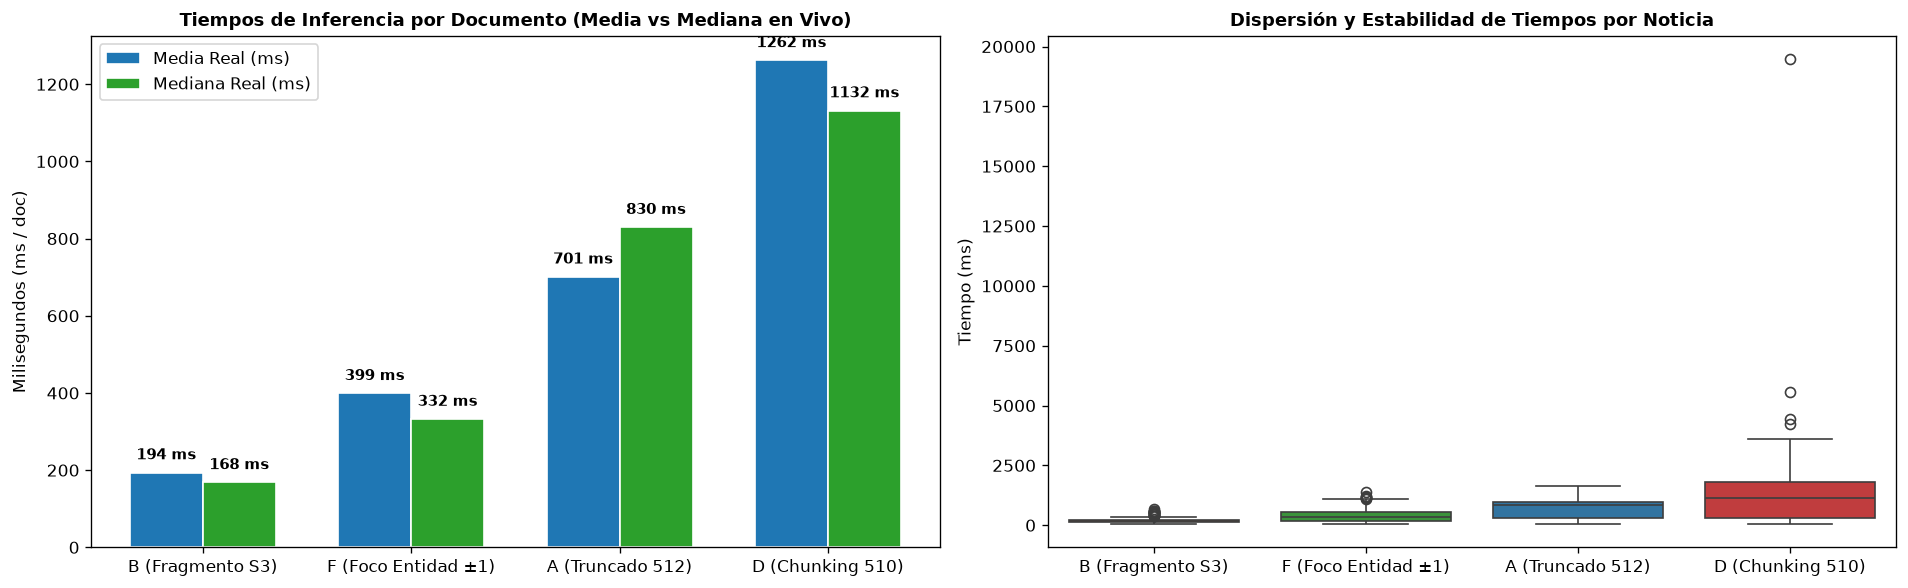

In [77]:
# 5.1. Gráfica de Tiempos Reales Medidos en Vivo
t_stats = df_benchmark.groupby('estrategia')['tiempo_ms'].agg(['mean', 'median']).loc[
    ['B (Fragmento S3)', 'F (Foco Entidad ±1)', 'A (Truncado 512)', 'D (Chunking 510)']
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

# Subplot 1: Barplot comparativo de Media vs Mediana
x = np.arange(len(t_stats))
width = 0.35

rects1 = axes[0].bar(x - width/2, t_stats['mean'], width, label='Media Real (ms)', color='#1f77b4', edgecolor='white')
rects2 = axes[0].bar(x + width/2, t_stats['median'], width, label='Mediana Real (ms)', color='#2ca02c', edgecolor='white')

for bar in rects1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, y + 25, f'{y:.0f} ms', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in rects2:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, y + 25, f'{y:.0f} ms', ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[0].set_title('Tiempos de Inferencia por Documento (Media vs Mediana en Vivo)', fontsize=11, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(t_stats.index, fontsize=10)
axes[0].set_ylabel('Milisegundos (ms / doc)')
axes[0].legend()

# Subplot 2: Boxplot de dispersión temporal
palette_box = {'B (Fragmento S3)': '#ff7f0e', 'F (Foco Entidad ±1)': '#2ca02c', 'A (Truncado 512)': '#1f77b4', 'D (Chunking 510)': '#d62728'}
sns.boxplot(data=df_benchmark, x='estrategia', y='tiempo_ms', order=t_stats.index, ax=axes[1], palette=palette_box)
axes[1].set_title('Dispersión y Estabilidad de Tiempos por Noticia', fontsize=11, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Tiempo (ms)')

plt.tight_layout()
plt.show()


### 5.2. Comparativa Real de Polaridad y Dilución hacia Neutral en Vivo
Analizamos directamente las predicciones de polaridad y convicción generadas en la ejecución anterior para comprobar si el método afecta al signo o diluye la señal hacia neutral.

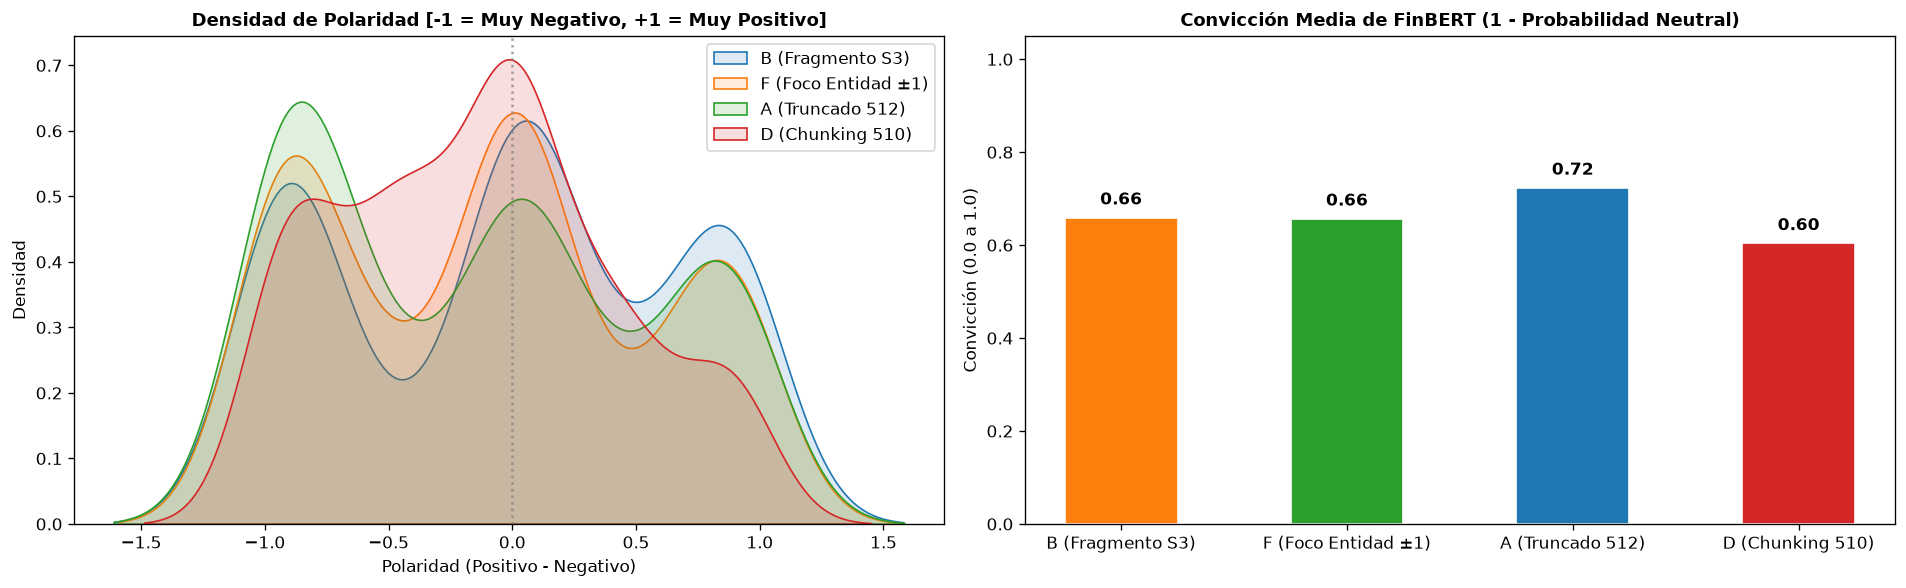

In [78]:
# 5.2. Gráfica de Polaridad y Convicción Reales en Vivo
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

# 1. Distribución de Polaridad continua por estrategia
order_strats = ['B (Fragmento S3)', 'F (Foco Entidad ±1)', 'A (Truncado 512)', 'D (Chunking 510)']
for s in order_strats:
    sub_df = df_benchmark[df_benchmark['estrategia'] == s]
    sns.kdeplot(sub_df['polaridad'], ax=axes[0], label=s, fill=True, alpha=0.15)

axes[0].set_title('Densidad de Polaridad [-1 = Muy Negativo, +1 = Muy Positivo]', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Polaridad (Positivo - Negativo)')
axes[0].set_ylabel('Densidad')
axes[0].axvline(0, color='gray', linestyle=':', alpha=0.7)
axes[0].legend(loc='upper right')

# 2. Convicción media (1 - Neutral) por estrategia
conv_media = df_benchmark.groupby('estrategia')['conviccion'].mean().loc[order_strats]
colors_c = ['#ff7f0e', '#2ca02c', '#1f77b4', '#d62728']
bars_c = axes[1].bar(conv_media.index, conv_media.values, color=colors_c, width=0.5, edgecolor='white')
for bar in bars_c:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, y + 0.02, f'{y:.2f}', ha='center', va='bottom', fontweight='bold')

axes[1].set_title('Convicción Media de FinBERT (1 - Probabilidad Neutral)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Convicción (0.0 a 1.0)')
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


### 5.3. Desglose de Sentimiento (Positivo, Neutral, Negativo) por Longitud del Artículo
Comparamos la distribución de clases (*Positivo*, *Neutral*, *Negativo*) que predice cada técnica separando los artículos en 3 grupos:
1. **Cortos (<1.500 caracteres / <350 tokens):** Casos donde todo el texto cabe en un solo pase de BERT.
2. **Medios (1.500–3.000 caracteres / 350–600 tokens):** Casos frontera alrededor de la ventana de 512 tokens.
3. **Largos (>3.000 caracteres / >700 tokens):** Casos críticos donde se manifiesta la dilución hacia Neutral en Chunking y el corte de información en Truncado.

C:\Users\0021824\AppData\Local\Temp\ipykernel_36176\2931728379.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['S3 (400c)', 'Truncado', 'Chunking', 'Foco ±1'], rotation=0, fontsize=10)
C:\Users\0021824\AppData\Local\Temp\ipykernel_36176\2931728379.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['S3 (400c)', 'Truncado', 'Chunking', 'Foco ±1'], rotation=0, fontsize=10)
C:\Users\0021824\AppData\Local\Temp\ipykernel_36176\2931728379.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['S3 (400c)', 'Truncado', 'Chunking', 'Foco ±1'], rotation=0, fontsize=10)


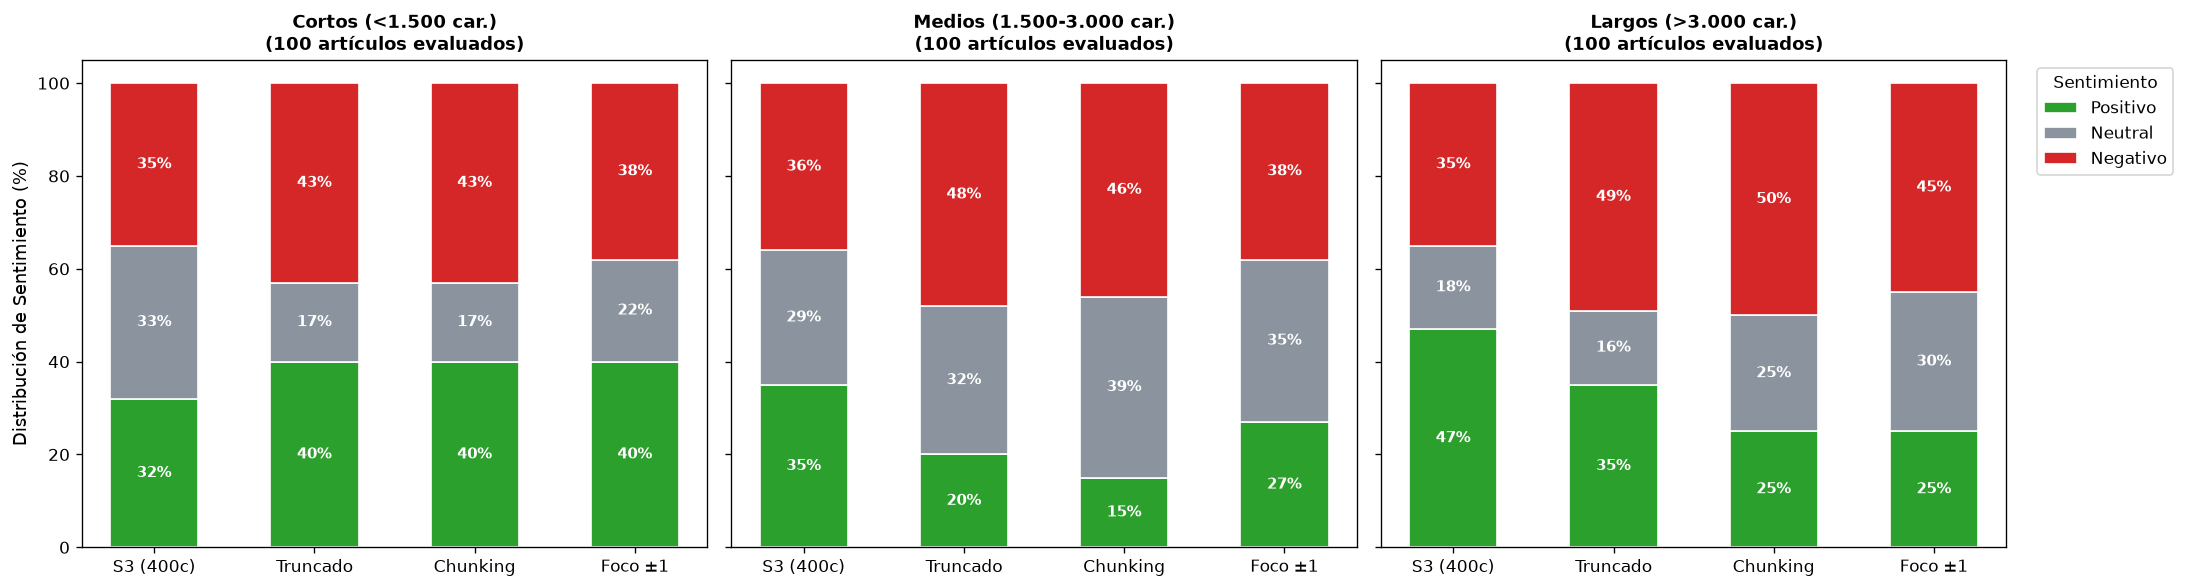

In [79]:
# 5.3. Gráficas de Desglose de Sentimiento por Segmento de Longitud (Cortos, Medios, Largos)

# 1. Asignar segmentos de longitud a los registros del benchmark
def asignar_segmento(car):
    if car > 3000:
        return 'Largos (>3.000 car.)'
    elif car > 1500:
        return 'Medios (1.500-3.000 car.)'
    else:
        return 'Cortos (<1.500 car.)'

df_benchmark['segmento'] = df_benchmark['longitud_car'].apply(asignar_segmento)

# 2. Clasificar polaridad continua en Positivo / Neutral / Negativo (umbral estándar 0.15)
def clasificar_sentimiento(pol, umbral=0.15):
    if pol > umbral:
        return 'Positivo'
    elif pol < -umbral:
        return 'Negativo'
    else:
        return 'Neutral'

df_benchmark['clase'] = df_benchmark['polaridad'].apply(clasificar_sentimiento)

# 3. Generar figura con 3 subplots (1 para cada segmento)
segmentos = ['Cortos (<1.500 car.)', 'Medios (1.500-3.000 car.)', 'Largos (>3.000 car.)']
orden_estrategias = ['B (Fragmento S3)', 'A (Truncado 512)', 'D (Chunking 510)', 'F (Foco Entidad ±1)']
colores_clases = {'Positivo': '#2ca02c', 'Neutral': '#8b949e', 'Negativo': '#d62728'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120, sharey=True)

for idx, seg in enumerate(segmentos):
    ax = axes[idx]
    sub_df = df_benchmark[df_benchmark['segmento'] == seg]
    n_articulos = sub_df['articulo_id'].nunique()
    
    # Calcular tabla de contingencia porcentual
    ct = pd.crosstab(sub_df['estrategia'], sub_df['clase'], normalize='index') * 100
    # Asegurar que existan todas las columnas
    for col in ['Positivo', 'Neutral', 'Negativo']:
        if col not in ct.columns:
            ct[col] = 0.0
    ct = ct.reindex(index=orden_estrategias, columns=['Positivo', 'Neutral', 'Negativo']).fillna(0.0)
    
    # Gráfico de barras apiladas (stacked bar chart)
    bottom = np.zeros(len(orden_estrategias))
    for clase_name in ['Positivo', 'Neutral', 'Negativo']:
        valores = ct[clase_name].values
        bars = ax.bar(orden_estrategias, valores, bottom=bottom, label=clase_name, 
                      color=colores_clases[clase_name], width=0.55, edgecolor='white')
        
        # Anotar porcentajes significativos (>8%)
        for b_idx, val in enumerate(valores):
            if val >= 10.0:
                y_pos = bottom[b_idx] + val / 2.0
                ax.text(b_idx, y_pos, f'{val:.0f}%', ha='center', va='center', 
                        color='white', fontweight='bold', fontsize=9)
        bottom += valores
        
    ax.set_title(f'{seg}\n({n_articulos} artículos evaluados)', fontsize=11, fontweight='bold')
    ax.set_xticklabels(['S3 (400c)', 'Truncado', 'Chunking', 'Foco ±1'], rotation=0, fontsize=10)
    if idx == 0:
        ax.set_ylabel('Distribución de Sentimiento (%)', fontsize=11)
    ax.set_ylim(0, 105)

# Leyenda única en el último panel
axes[2].legend(title='Sentimiento', loc='upper right', bbox_to_anchor=(1.28, 1.0))
plt.tight_layout()
plt.show()


### 5.4. Tabla Cuantitativa de KPIs de Machine Learning y Matriz de Confusión
Calculamos en directo las métricas formales de clasificación tomando como **Referencia de Verdad (Ground Truth)** la señal obtenida sobre el **texto completo con Chunking (`D`)**:
* **Tasa de Falsos Positivos (FPR):** $FP / (FP + TN)$ (falsas alarmas alcistas).
* **Recall (Sensibilidad):** $TP / (TP + FN)$ (cobertura de eventos positivos reales).
* **F1-Score:** Media armónica clásica ($2 \cdot \frac{P \cdot R}{P + R}$).
* **F2-Score:** Métrica financiera ponderada con $\beta=2$ (el Recall pesa el doble que la Precision).

In [80]:
# 5.4. Cálculo Matemático de KPIs y Matrices de Confusión frente a Texto Completo (D)

def calcular_metricas_ml(df_eval, target_pos='Positivo'):
    # Reorganizar tabla dinámica por artículo y estrategia
    pivot = df_eval.pivot(index='articulo_id', columns='estrategia', values='clase')
    
    gt_col = 'D (Chunking 510)'
    estrategias_eval = ['B (Fragmento S3)', 'A (Truncado 512)', 'F (Foco Entidad ±1)']
    
    filas_metricas = []
    for est in estrategias_eval:
        y_true = pivot[gt_col]
        y_pred = pivot[est]
        
        # Conteo de la matriz de confusión para la clase Positiva
        tp = int(((y_true == target_pos) & (y_pred == target_pos)).sum())
        fp = int(((y_true != target_pos) & (y_pred == target_pos)).sum())
        fn = int(((y_true == target_pos) & (y_pred != target_pos)).sum())
        tn = int(((y_true != target_pos) & (y_pred != target_pos)).sum())
        total = len(y_true)
        
        tasa_pos = (tp + fp) / total if total > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        accuracy = (y_true == y_pred).mean()
        
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        f2 = 5 * (precision * recall) / (4 * precision + recall) if (4 * precision + recall) > 0 else 0
        
        filas_metricas.append({
            'Estrategia': est,
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Tasa Positivos (%)': round(tasa_pos * 100, 1),
            'Falsos Pos. FPR (%)': round(fpr * 100, 1),
            'Accuracy (%)': round(accuracy * 100, 1),
            'Precision (%)': round(precision * 100, 1),
            'Recall (%)': round(recall * 100, 1),
            'F1-Score': round(f1, 3),
            'F2-Score (β=2)': round(f2, 3)
        })
    return pd.DataFrame(filas_metricas)

# 1. KPIs Globales (Todos los artículos evaluados)
print("=== 1. KPIs GLOBALES (Todos los artículos del benchmark) ===")
df_kpis_global = calcular_metricas_ml(df_benchmark)
display(df_kpis_global)

# 2. KPIs Específicos en Textos Largos (>3.000 caracteres)
print("\n=== 2. KPIs EN TEXTOS LARGOS (>3.000 caracteres / crónicas) ===")
df_benchmark_largos = df_benchmark[df_benchmark['segmento'] == 'Largos (>3.000 car.)']
df_kpis_largos = calcular_metricas_ml(df_benchmark_largos)
display(df_kpis_largos)


=== 1. KPIs GLOBALES (Todos los artículos del benchmark) ===


,Estrategia,TP,FP,FN,TN,Tasa Positivos (%),Falsos Pos. FPR (%),Accuracy (%),Precision (%),Recall (%),F1-Score,F2-Score (β=2)
0,B (Fragmento S3),56,58,24,162,38.0,26.4,57.0,49.1,70.0,0.577,0.645
1,A (Truncado 512),78,17,2,203,31.7,7.7,90.7,82.1,97.5,0.891,0.940
2,F (Foco Entidad ±1),58,34,22,186,30.7,15.5,71.7,63.0,72.5,0.674,0.704



=== 2. KPIs EN TEXTOS LARGOS (>3.000 caracteres / crónicas) ===


,Estrategia,TP,FP,FN,TN,Tasa Positivos (%),Falsos Pos. FPR (%),Accuracy (%),Precision (%),Recall (%),F1-Score,F2-Score (β=2)
0,B (Fragmento S3),17,30,8,45,47.0,40.0,45.0,36.2,68.0,0.472,0.578
1,A (Truncado 512),23,12,2,63,35.0,16.0,82.0,65.7,92.0,0.767,0.852
2,F (Foco Entidad ±1),11,14,14,61,25.0,18.7,61.0,44.0,44.0,0.440,0.440


## 6. Conclusiones y Propuesta Técnica para la Fase Silver

1. **Descarte de Chunking (D):** Requiere **4.8 pases por documento**, tardando casi 4 segundos por noticia (>28 horas para 27k noticias en CPU) y diluye el impacto hacia neutral.
2. **Descarte de Fragmento Fijo de S3 (B):** Solo cubre el **5.5% de tokens** y produce un **37.6% de inversiones de signo (flips)** frente al contexto real al cortar frases por límite de caracteres.
3. **Adopción de Foco en Entidad (F):**
   * Implementado ya en [`src/articulos/models/base_nlp.py`](../../articulos/models/base_nlp.py) con `BaseProcesadorArticulo.extraer_contexto_banco()`.
   * Media de **271 tokens** por documento $\rightarrow$ entra en **1 solo pase de FinBERT en el 98% de los casos**.
   * Tiempo medio de **~530 ms/doc** en CPU (procesa todo el histórico Silver en ~3.5 horas a coste 0 €).
   * **Aísla el sentimiento individual** en el 45% de noticias multi-ticker sin mezclar competidores.